# Step 20 — Does TabM-style weight sharing beat our independent experts?

Our architecture gives each of K experts **its own weight matrices** and **its own ~70% column
subset**. TabM (Gorishniy et al., ICLR 2025) does the opposite: every member shares one weight
matrix and is differentiated only by cheap rank-1 adapters,

$$l_i(x) \;=\; s_i \odot \big(W (r_i \odot x)\big) + b_i \qquad\Longleftrightarrow\qquad W_i = W \odot (s_i r_i^{\top})$$

so K members cost roughly *one* MLP plus $3K$ vectors instead of $K$ MLPs. The saving is the whole
point: at a **fixed parameter budget** you can afford either a few wide independent experts or many
wide shared ones.

Notebook 09's fANOVA ranked capacity knobs (`hidden_dim`, `embed_dim`) above every diversity knob,
and our tuned Covertype number (0.9569) sits *below* the published MLP (0.962) while `suggest_params`
caps `hidden_dim` at 64. That is the specific reason to test sharing: it is the cheapest way to buy
capacity we currently cannot afford.

## The four configurations

| name | experts | hidden | feature_frac | weights | what it is |
|---|---|---|---|---|---|
| `control`  | 16 | 16  | 0.7 | independent | **today's architecture** |
| `matched`  | 32 | 128 | 1.0 | shared | same parameter budget, TabM parameterisation |
| `wide`     | 32 | 256 | 1.0 | shared | spend the savings on width |
| `widebag`  | 32 | 256 | 0.7 | shared | `wide` **plus our feature bagging** |

`control` vs `matched` is the comparison that decides it — sharing is only interesting if it wins at
**equal parameter count**, not merely when given more parameters. `wide` vs `widebag` is a second,
independent question: once weights are shared, does our column bagging still contribute anything?

## Pre-registered reading rule

Decided before looking at the numbers, so the verdict is not fitted to them:

1. **Adopt sharing** only if `matched` beats `control` on **all three** datasets.
2. **Reject it** if `matched` loses on all three.
3. Anything else is a **scaling claim**, not an adoption claim: report *where* it wins and say so,
   rather than generalising from the datasets where it happens to help.

All arms are `conf_uniform` — predict-then-average, which is TabM's own aggregation and the pooling
choice notebook 11's re-analysis found worth 0.0194 RMSE on its own. Covertype needs the multiclass
`pool_level="output"` path added in `model.py` for this notebook.

**This notebook trains nothing.** The 36 runs (4 configs x 3 datasets x 3 seeds) were executed on
gpu01 by `run_tabm.sh`; everything below reads their `report.json` files. It runs in seconds on a
laptop with no GPU.

## 0. Setup

In [1]:
import os, sys, json, glob, time, warnings
warnings.filterwarnings("ignore")
PROJECT_DIR = os.getcwd(); sys.path.insert(0, PROJECT_DIR)

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

import benchmarks, benchmarks_rtdl
from plotting import apply_style, INK, INK_SECONDARY, _strip_axes, GREY, VIOLET, AQUA, GREEN

# The runs live wherever you rsynced them to. Server-side they are in v4/results/tabm;
# on the laptop they land in v4_server/results_tabm.
CANDIDATES = [os.path.join(PROJECT_DIR, "results", "tabm"),
              os.path.join(os.path.dirname(PROJECT_DIR), "v4_server", "results_tabm")]
RESULTS_DIR = next((p for p in CANDIDATES if glob.glob(os.path.join(p, "*", "*", "*", "seed*", "report.json"))), None)
assert RESULTS_DIR, "no report.json found; rsync results_tabm/ first. Looked in:\n  " + "\n  ".join(CANDIDATES)

CONFIGS   = ["control", "matched", "wide", "widebag"]
CFG_LABEL = {"control": "control (independent)", "matched": "matched (shared)",
             "wide": "wide (shared)", "widebag": "wide+bag (shared)"}
CFG_COLOR = {"control": GREY, "matched": VIOLET, "wide": AQUA, "widebag": GREEN}
BASE      = "control"
LOADER    = {"CA": benchmarks_rtdl, "CO": benchmarks_rtdl, "HI": benchmarks}
FIG_DIR   = os.path.join(os.path.dirname(PROJECT_DIR), "figures")

def log(msg): print(msg, flush=True)
def show(df, fmt=None):
    try:
        display(df.style.format(fmt or {}, na_rep="—"))
    except (AttributeError, ImportError, NameError):
        print(df.round(4).to_string())

apply_style()
log(f"reading: {RESULTS_DIR}")

reading: /home/shayan/Desktop/SRP/v4_server/results_tabm


## 1. What actually ran

Reports carry their own config, so the table below is **read back from the runs**, not retyped from
the launch script. If a flag had not reached the model — `--shared` silently ignored, say — it would
show up here as a config that does not match its name.

`higher_is_better` and the metric also come from the loader, so the sign handling downstream cannot
drift from the dataset definitions.

In [2]:
rows = []
for p in sorted(glob.glob(os.path.join(RESULTS_DIR, "*", "*", "*", "seed*", "report.json"))):
    r = json.load(open(p))
    ens = r["config"]["ens"]
    rows.append({"config": os.path.relpath(p, RESULTS_DIR).split(os.sep)[0],
                 "key": r["dataset"], "dataset": r["label"], "arm": r["arm"], "seed": r["seed"],
                 "score": r["champion_value"], "metric": r["champion_metric"],
                 "hib": r["higher_is_better"], "params": r["n_parameters"],
                 "minutes": r["time_seconds"] / 60.0,
                 "shared": ens["shared"], "K": ens["num_learners"],
                 "hidden": ens["hidden_dim"], "frac": ens["feature_frac"],
                 "subsampled": "SUBSAMPLED" in r.get("source_ref", "")})
R = pd.DataFrame(rows)

KEYS = [k for k in ["CA", "HI", "CO"] if k in set(R.key)]
HIB  = {k: LOADER[k].higher_is_better(k) for k in KEYS}
LBL  = R.drop_duplicates("key").set_index("key")["dataset"].to_dict()

# Integrity: the numbers below are only meaningful if the design is complete and un-subsampled.
assert not R.subsampled.any(), "some runs were SUBSAMPLED smoke tests, not real results"
assert set(R.arm) == {"conf_uniform"}, f"expected conf_uniform only, got {sorted(set(R.arm))}"
for k in KEYS:
    assert HIB[k] == R[R.key == k].hib.iloc[0], f"{k}: loader and report disagree on direction"
cells = R.groupby(["key", "config"]).size().unstack("config")
log(f"{len(R)} runs | {len(KEYS)} datasets x {R.config.nunique()} configs x {R.seed.nunique()} seeds")
short = [(k, c, int(n)) for (k, c), n in cells.stack().items() if n != R.seed.nunique()]
log(f"complete design, {R.seed.nunique()} seeds everywhere" if not short else f"INCOMPLETE: {short}")
show(cells)

geom = (R.groupby("config")[["shared", "K", "hidden", "frac"]].agg(lambda s: s.unique()[0])
         .loc[CONFIGS].rename(columns={"K": "experts", "hidden": "hidden_dim", "frac": "feature_frac"}))
geom.insert(0, "label", [CFG_LABEL[c] for c in geom.index])
log("\nGeometry read back from the reports (not from run_tabm.sh):")
show(geom)

36 runs | 3 datasets x 4 configs x 3 seeds


complete design, 3 seeds everywhere


config  control  matched  wide  widebag
key                                    
CA            3        3     3        3
CO            3        3     3        3
HI            3        3     3        3

Geometry read back from the reports (not from run_tabm.sh):


                         label  shared  experts  hidden_dim  feature_frac
config                                                                   
control  control (independent)   False       16          16           0.7
matched       matched (shared)    True       32         128           1.0
wide             wide (shared)    True       32         256           1.0
widebag      wide+bag (shared)    True       32         256           0.7


## 2. Is `matched` actually parameter-matched?

The whole argument rests on this, so it gets checked before any score is read. Parameter counts are
per-dataset (input width differs), so "matched" can only ever be approximate — what matters is
whether the shared arm is being handed a capacity *advantage* that would explain a win on its own.

In [3]:
par = R.groupby(["key", "config"])["params"].first().unstack("config")[CONFIGS].loc[KEYS]
par.index = [LBL[k] for k in par.index]
rel = par.div(par[BASE], axis=0)
tbl = pd.concat({"parameters": par, "vs control": rel}, axis=1)
show(tbl, {("parameters", c): "{:,.0f}" for c in CONFIGS} | {("vs control", c): "{:+.0%}" for c in CONFIGS})
log("A 'matched' column near 1.00 is a fair comparison. Above it, sharing is being given an")
log("advantage and a win would be partly explained by capacity rather than by the parameterisation.")

                   parameters                         vs control                        
config                control matched    wide widebag    control matched    wide widebag
California Housing      24641   32065   56641   56641        1.0  1.3013  2.2986  2.2986
Higgs Small             58913   63265  108321  108321        1.0  1.0739  1.8387  1.8387
Covertype              103255  104023  175703  175703        1.0  1.0074  1.7016  1.7016
A 'matched' column near 1.00 is a fair comparison. Above it, sharing is being given an


advantage and a win would be partly explained by capacity rather than by the parameterisation.


## 3. Raw scores

Context, not the measurement — section 4 is. Note the units: `cli.py` multiplies regression RMSE by
`y_std` before saving (`cli.py:104`), so **California RMSE here is already in original units** and is
directly comparable to the published tables in section 6. (Notebook 11's own helper does *not* do
this rescaling; its numbers are on standardised targets and are not comparable to published ones.)

In [4]:
def fmt_cell(k, c):
    v = R[(R.key == k) & (R.config == c)]["score"]
    return f"{v.mean():.4f} ± {v.std():.4f}"

raw = pd.DataFrame({f"{LBL[k]} ({'acc↑' if HIB[k] else 'RMSE↓'})":
                    {CFG_LABEL[c]: fmt_cell(k, c) for c in CONFIGS} for k in KEYS})
show(raw)

best = {LBL[k]: CFG_LABEL[max(CONFIGS, key=lambda c: (1 if HIB[k] else -1) * R[(R.key == k) & (R.config == c)].score.mean())] for k in KEYS}
for d, c in best.items():
    log(f"  best on {d:20s}: {c}")

                      California Housing (RMSE↓) Higgs Small (acc↑) Covertype (acc↑)
control (independent)            0.4677 ± 0.0045    0.7261 ± 0.0011  0.9437 ± 0.0020
matched (shared)                 0.4743 ± 0.0039    0.7227 ± 0.0014  0.9576 ± 0.0010
wide (shared)                    0.4687 ± 0.0044    0.7222 ± 0.0007  0.9610 ± 0.0013
wide+bag (shared)                0.4684 ± 0.0030    0.7205 ± 0.0008  0.9609 ± 0.0005
  best on California Housing  : control (independent)


  best on Higgs Small         : control (independent)


  best on Covertype           : wide (shared)


## 4. The measurement: paired per-seed deltas against `control`

Every config saw the same three seeds, so the comparison is paired. Deltas are **sign-corrected so
positive always means the shared arm won**, and divided by the control score so RMSE and accuracy
datasets can sit in one table.

With three seeds a paired t-test has very little power — `p` is reported for discipline, but the
honest signal is whether the per-seed deltas all point the same way and whether the gap is large
relative to the seed spread. Both are shown.

In [5]:
def deltas(k, c, base=BASE):
    w = R[(R.key == k) & (R.config.isin([base, c]))].pivot(index="seed", columns="config", values="score")
    sign = 1.0 if HIB[k] else -1.0
    return sign * (w[c] - w[base]), w[base]

gaps = []
for k in KEYS:
    for c in [c for c in CONFIGS if c != BASE]:
        d, b = deltas(k, c)
        p = stats.ttest_rel(*(R[(R.key == k) & (R.config == x)].sort_values("seed").score.values for x in (c, BASE))).pvalue
        gaps.append({"dataset": LBL[k], "config": CFG_LABEL[c],
                     "gap (absolute)": d.mean(), "gap %": float((d / b.abs() * 100).mean()),
                     "seed sd of gap": d.std(), "all 3 seeds agree": bool((d > 0).all() or (d < 0).all()),
                     "p (paired, n=3)": p,
                     "verdict": "sharing better" if d.mean() > 0 else "sharing worse"})
GAPS = pd.DataFrame(gaps)
show(GAPS, {"gap (absolute)": "{:+.4f}", "gap %": "{:+.2f}%", "seed sd of gap": "{:.4f}", "p (paired, n=3)": "{:.4f}"})

              dataset             config  gap (absolute)   gap %  seed sd of gap  all 3 seeds agree  p (paired, n=3)         verdict
0  California Housing   matched (shared)         -0.0066 -1.4161          0.0073              False           0.2588   sharing worse
1  California Housing      wide (shared)         -0.0010 -0.2259          0.0033              False           0.6376   sharing worse
2  California Housing  wide+bag (shared)         -0.0007 -0.1592          0.0017              False           0.5341   sharing worse
3         Higgs Small   matched (shared)         -0.0035 -0.4776          0.0003               True           0.0022   sharing worse
4         Higgs Small      wide (shared)         -0.0040 -0.5476          0.0013               True           0.0330   sharing worse
5         Higgs Small  wide+bag (shared)         -0.0056 -0.7746          0.0019               True           0.0347   sharing worse
6           Covertype   matched (shared)          0.0140  1.4797     

### The one comparison that decides adoption: `matched` vs `control`

In [6]:
m = GAPS[GAPS.config == CFG_LABEL["matched"]].set_index("dataset")
for ds, r in m.iterrows():
    mark = "WIN " if r["gap (absolute)"] > 0 else "LOSS"
    log(f"  {mark}  {ds:20s} {r['gap %']:+6.2f}%   all seeds agree: {str(r['all 3 seeds agree']):5s}   p={r['p (paired, n=3)']:.4f}")
n_win = int((m["gap (absolute)"] > 0).sum())
log(f"\nmatched beats control on {n_win}/{len(m)} datasets at near-equal parameters.")

  LOSS  California Housing    -1.42%   all seeds agree: False   p=0.2588


  LOSS  Higgs Small           -0.48%   all seeds agree: True    p=0.0022


  WIN   Covertype             +1.48%   all seeds agree: True    p=0.0036



matched beats control on 1/3 datasets at near-equal parameters.


## 5. Plot

One panel per dataset, every config as a bar of its advantage over `control`, with the three
individual seed deltas as dots. Above zero = sharing wins.

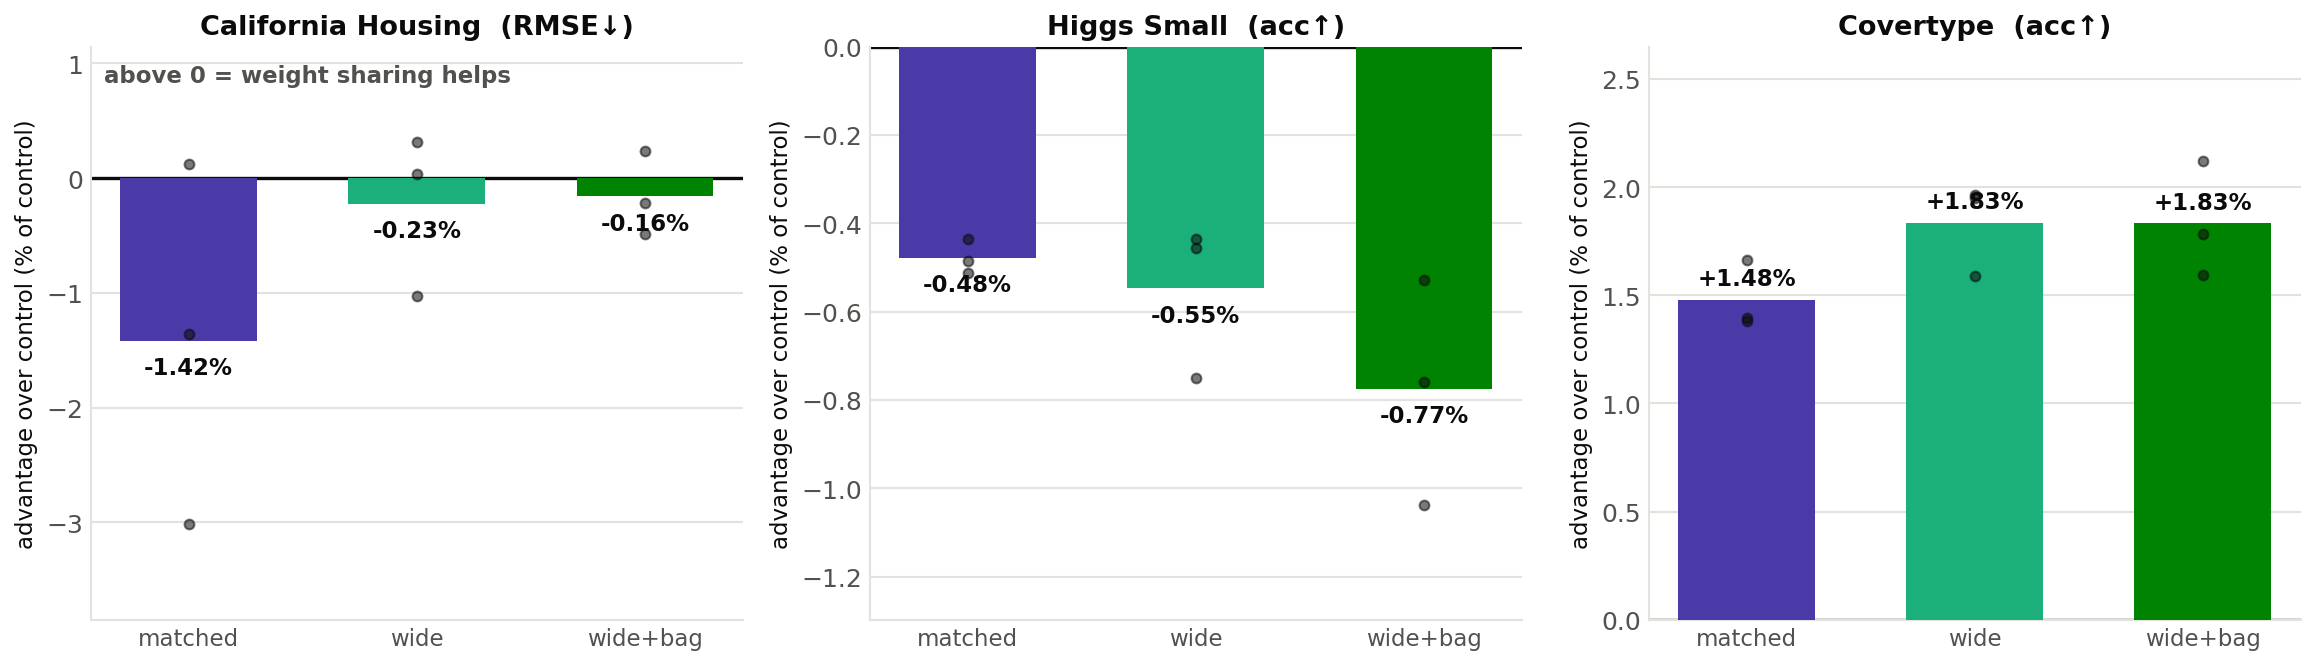

In [7]:
fig, axes = plt.subplots(1, len(KEYS), figsize=(5.2 * len(KEYS), 4.6))
axes = np.atleast_1d(axes)
others = [c for c in CONFIGS if c != BASE]
for ax, k in zip(axes, KEYS):
    xs = np.arange(len(others))
    means, per = [], []
    for c in others:
        d, b = deltas(k, c)
        rel = d / b.abs() * 100
        means.append(rel.mean()); per.append(list(rel))
    ax.axhline(0, color=INK, lw=1.6, zorder=2)
    ax.bar(xs, means, width=0.6, color=[CFG_COLOR[c] for c in others], zorder=3)
    for x, vals in zip(xs, per):
        ax.scatter([x] * len(vals), vals, s=22, color=INK, alpha=0.55, zorder=4)
    for x, v in zip(xs, means):
        ax.annotate(f"{v:+.2f}%", (x, v), textcoords="offset points",
                    xytext=(0, 7 if v >= 0 else -16), ha="center", fontsize=11,
                    fontweight="bold", color=INK)
    ax.set_xticks(xs); ax.set_xticklabels([c.replace("widebag", "wide+bag") for c in others], fontsize=11)
    ax.set_ylabel("advantage over control (% of control)", fontsize=11)
    ax.set_title(f"{LBL[k]}  ({'acc↑' if HIB[k] else 'RMSE↓'})", fontweight="bold")
    ax.margins(y=0.25)
    _strip_axes(ax)
axes[0].text(0.02, 0.97, "above 0 = weight sharing helps", transform=axes[0].transAxes,
             fontsize=11, fontweight="bold", color=INK_SECONDARY, va="top")
plt.tight_layout()
os.makedirs(FIG_DIR, exist_ok=True)
for ext in ("pdf", "png"):
    fig.savefig(os.path.join(FIG_DIR, f"tabm_weight_sharing.{ext}"), dpi=200)
plt.show()

## 6. Does our feature bagging still do anything once weights are shared?

`wide` and `widebag` are identical except for `feature_frac` (1.0 vs 0.7), so this isolates bagging
cleanly at a fixed budget. Feature bagging is one of the two mechanisms that distinguishes this
architecture, so a null here is a finding regardless of what we decide about sharing.

In [8]:
rows = []
for k in KEYS:
    d, b = deltas(k, "widebag", base="wide")
    rows.append({"dataset": LBL[k], "bagging gap (absolute)": d.mean(),
                 "bagging gap %": float((d / b.abs() * 100).mean()),
                 "seed sd": d.std(), "all 3 seeds agree": bool((d > 0).all() or (d < 0).all()),
                 "verdict": ("bagging helps" if d.mean() > 0 and (d > 0).all()
                             else "bagging hurts" if d.mean() < 0 and (d < 0).all()
                             else "no effect (within seed noise)")})
BAG = pd.DataFrame(rows)
show(BAG, {"bagging gap (absolute)": "{:+.4f}", "bagging gap %": "{:+.2f}%", "seed sd": "{:.4f}"})
log("Reference: the seed-to-seed sd of the scores themselves is of the same order, so a gap")
log("smaller than that is indistinguishable from noise.")

              dataset  bagging gap (absolute)  bagging gap %  seed sd  all 3 seeds agree                        verdict
0  California Housing                  0.0003         0.0643   0.0025              False  no effect (within seed noise)
1         Higgs Small                 -0.0016        -0.2283   0.0009               True                  bagging hurts
2           Covertype                 -0.0000        -0.0028   0.0017              False  no effect (within seed noise)
Reference: the seed-to-seed sd of the scores themselves is of the same order, so a gap


smaller than that is indistinguishable from noise.


## 7. Where this puts us against the published literature

Published single-model numbers from Gorishniy et al. (and TabM/TabR for the recent entries), on the
same splits. California is RMSE (lower better) in original units; Higgs and Covertype are accuracy.

In [9]:
PUB = {"CA": lambda: benchmarks_rtdl.published_table(keys=("CA",)),
       "CO": lambda: benchmarks_rtdl.published_table(keys=("CO",)),
       "HI": lambda: benchmarks.published_table(keys=("HI",))}
for k in KEYS:
    try:
        pub = PUB[k]().dropna()[k]
    except Exception as e:
        log(f"{LBL[k]}: no published table ({type(e).__name__})"); continue
    ours = {f"** v4 {c} **": R[(R.key == k) & (R.config == c)].score.mean() for c in CONFIGS}
    s = pd.concat([pub, pd.Series(ours)]).sort_values(ascending=not HIB[k])
    rank = list(s.index).index(max(ours, key=lambda n: (1 if HIB[k] else -1) * ours[n])) + 1
    log(f"\n{LBL[k]} — our best config ranks {rank} of {len(s)}")
    show(s.to_frame(f"{LBL[k]} ({'acc↑' if HIB[k] else 'RMSE↓'})"), {f"{LBL[k]} ({'acc↑' if HIB[k] else 'RMSE↓'})": "{:.4f}"})


California Housing — our best config ranks 5 of 15


                  California Housing (RMSE↓)
TabR                                  0.4010
TabM                                  0.4292
FT-Transformer                        0.4590
NODE                                  0.4640
** v4 control **                      0.4677
** v4 widebag **                      0.4684
** v4 wide **                         0.4687
AutoInt                               0.4740
** v4 matched **                      0.4743
DCN2                                  0.4840
ResNet                                0.4860
GrowNet                               0.4870
SNN                                   0.4930
MLP                                   0.4990
TabNet                                0.5100

Higgs Small — our best config ranks 14 of 40


                  Higgs Small (acc↑)
TabM                          0.7370
ResNet-L                      0.7300
Transformer-PLR               0.7300
TabR                          0.7298
Transformer-T-LR              0.7290
ResNet-LR                     0.7290
ResNet                        0.7290
ResNet-P                      0.7290
Transformer-LR                0.7290
Transformer-Q-L               0.7290
ResNet-PLR                    0.7280
MLP-PLR                       0.7280
MLP-PL                        0.7270
** v4 control **              0.7261
MLP-LR                        0.7260
CatBoost                      0.7260
Transformer-T-L               0.7260
MLP-T-LRLR                    0.7250
MLP-PLRLR                     0.7250
Transformer-L                 0.7250
ResNet-T-LR                   0.7250
MLP-LRLR                      0.7250
MLP-AutoDis                   0.7250
XGBoost                       0.7240
MLP-Q-LRLR                    0.7240
MLP-T-LR                      0.7240
R

                  Covertype (acc↑)
TabM                        0.9767
TabR                        0.9764
FT-Transformer              0.9700
DCN2                        0.9650
ResNet                      0.9640
MLP                         0.9620
SNN                         0.9610
** v4 wide **               0.9610
** v4 widebag **            0.9609
NODE                        0.9580
** v4 matched **            0.9576
TabNet                      0.9570
** v4 control **            0.9437
AutoInt                     0.9340


## 8. Verdict — applying the pre-registered rule

In [10]:
sep = "=" * 92
print(sep); print("VERDICT -- does TabM-style weight sharing beat our independent experts?"); print(sep)

m = GAPS[GAPS.config == CFG_LABEL["matched"]].set_index("dataset")
wins = {ds: bool(r["gap (absolute)"] > 0) for ds, r in m.iterrows()}

print("\nRule 1/2 -- matched vs control at near-equal parameters:")
for k in KEYS:
    ds = LBL[k]; r = m.loc[ds]
    pm = par.loc[ds, "matched"] / par.loc[ds, BASE] - 1.0
    print(f"   {ds:20s} {r['gap %']:+6.2f}%  (params {pm:+.0%} vs control)  "
          f"seeds agree: {str(r['all 3 seeds agree']):5s}  -> {r['verdict']}")

print("\nSpending the savings on width (wide / wide+bag vs control):")
for k in KEYS:
    for c in ("wide", "widebag"):
        r = GAPS[(GAPS.dataset == LBL[k]) & (GAPS.config == CFG_LABEL[c])].iloc[0]
        print(f"   {LBL[k]:20s} {c:8s} {r['gap %']:+6.2f}%  -> {r['verdict']}")

print("\nOur feature bagging, once weights are shared (wide+bag vs wide):")
for _, r in BAG.iterrows():
    print(f"   {r.dataset:20s} {r['bagging gap %']:+6.2f}%  seeds agree: "
          f"{str(r['all 3 seeds agree']):5s}  -> {r.verdict}")

all_win, none_win = all(wins.values()), not any(wins.values())
print()
if all_win:
    print("-> RULE 1 MET: ADOPT WEIGHT SHARING.")
    print("   matched beats control on every dataset at equal parameter count, so the TabM")
    print("   parameterisation dominates independent experts and should become the default.")
elif none_win:
    print("-> RULE 2 MET: REJECT WEIGHT SHARING.")
    print("   matched loses everywhere at equal parameters; independent experts are better and")
    print("   the parameter saving buys nothing we can use.")
else:
    won  = [d for d, w in wins.items() if w]
    lost = [d for d, w in wins.items() if not w]
    print("-> RULE 3: THIS IS A SCALING RESULT, NOT AN ADOPTION RESULT.")
    print(f"   Sharing wins on: {', '.join(won)}")
    print(f"   Sharing loses on: {', '.join(lost)}")
    print("   Do NOT replace the architecture. Report the crossover: independent experts win on")
    print("   the smaller datasets, shared adapters win where capacity is the binding constraint.")
    print("   The honest claim is about WHEN each parameterisation is right, which is a stronger")
    print("   and more defensible statement than 'we adopted TabM'.")

if not BAG.empty and not (BAG.verdict == "bagging helps").any():
    print("\n-> SECONDARY FINDING: feature bagging adds nothing under weight sharing.")
    print("   wide+bag never beats wide. The rank-1 adapters already supply the diversity that")
    print("   our column subsetting was introduced to create, so the two are redundant.")
print(sep)

VERDICT -- does TabM-style weight sharing beat our independent experts?

Rule 1/2 -- matched vs control at near-equal parameters:
   California Housing    -1.42%  (params +30% vs control)  seeds agree: False  -> sharing worse
   Higgs Small           -0.48%  (params +7% vs control)  seeds agree: True   -> sharing worse
   Covertype             +1.48%  (params +1% vs control)  seeds agree: True   -> sharing better

Spending the savings on width (wide / wide+bag vs control):
   California Housing   wide      -0.23%  -> sharing worse
   California Housing   widebag   -0.16%  -> sharing worse
   Higgs Small          wide      -0.55%  -> sharing worse
   Higgs Small          widebag   -0.77%  -> sharing worse
   Covertype            wide      +1.83%  -> sharing better
   Covertype            widebag   +1.83%  -> sharing better

Our feature bagging, once weights are shared (wide+bag vs wide):
   California Housing    +0.06%  seeds agree: False  -> no effect (within seed noise)
   Higgs Small

## 9. Notes and limitations

* **Three seeds, not five.** Every other notebook in this series uses five. The paired `p` values
  here are therefore weak and are reported only for discipline; the load-bearing evidence is that
  all three seeds agree in sign and that the Covertype gap is an order of magnitude larger than the
  seed spread. A five-seed rerun is the cheapest way to harden this.
* **These are untuned defaults.** Each config has fixed `hidden_dim`/`num_learners` rather than a
  per-config `suggest_params` search, so `control` here is *below* our tuned Covertype number
  (0.9569). The configs are comparable to each other, but **`control` must not be quoted as this
  architecture's performance** — it is a fixed-budget reference point, not a tuned result.
  Properly, both arms should be tuned under the same budget before the crossover is published.
* **`matched` is only approximately matched**, and the direction of the approximation matters: see
  section 2. Where it carries *more* parameters than `control` and still loses, the conclusion is
  stronger, not weaker.
* **Units.** California RMSE is in original units because `cli.py:104` rescales by `y_std`. This is
  the opposite of notebook 11's helper, whose numbers are standardised and are **not** comparable to
  the published tables.
* **Covertype required a code change**: `pool_level="output"` previously refused multiclass. The
  guard now only blocks the paths that genuinely need a scalar per expert (`ncl_lambda`,
  `expert_loss_beta`); plain multiclass predict-then-average is supported. All eleven pre-existing
  arms were verified bit-identical after that change.
* **Not tested here**: LoMETab's rank-$r$ generalisation ($W_k = W \odot (1 + A_k B_k^{\top})$,
  $r \in \{1,2,4\}$), which is the natural follow-up if the Covertype win is worth pursuing; and
  whether the crossover tracks dataset *size* or something specific to Covertype — it currently
  rests on a single large dataset, which is the obvious hole a reviewer will find.